# with CASIM in simple model

In [1]:
import sys
import math
from datetime import datetime

import numpy as np
import matplotlib.pyplot as plt
from netCDF4 import Dataset # !! new - building netcdf
import os # file saving 
import xarray as xr
from pathlib import Path
import importlib.util
from glob import glob
import seaborn as sns
import imageio 
import tempfile

# with / without casim added

In [2]:
save_loc_v3_1 = "/gws/ssde/j25a/dcmex/users/ezriab/graupel_model_output/v4_1/" # location to save output files
save_name = 'v4_1'
ncfile_v4_1 = xr.open_dataset(f"{save_loc_v3_1}{save_name}.nc", decode_times=False)
ncfile_envi_v4_1 = xr.open_dataset(f"{save_loc_v3_1}{save_name}.nc", group="environment", engine="netcdf4",decode_times=False)
ncfile_ice_v4_1 = xr.open_dataset(f"{save_loc_v3_1}{save_name}.nc", group="ice_particles", engine="netcdf4",decode_times=False)
ncfile_splinter_v4_1 = xr.open_dataset(f"{save_loc_v3_1}{save_name}.nc", group="splinter_particles", engine="netcdf4",decode_times=False)

# also pull out the variables put into the namelist file
namelist_file = ncfile_v4_1.attrs["namelist_file"]
with open(namelist_file, "r") as f:
    namelist_contents = f.read()
namelist_v4_1 = {} ## all the namelist inputs are stored in this dictionary
exec(namelist_contents, {"np": np}, namelist_v4_1)

## pull out relevent functions
sys.path.append('/home/users/esree/simple-graupel-model/')
# i have moved all the smaller functions to a seperate file - so can be accessed when plotting too
from graupel_model_sub_functions import trev, ptz

/home/users/esree/miniforge3/envs/vs_code_envi/lib/python3.13/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


In [3]:
save_loc_v3_1 = "/gws/ssde/j25a/dcmex/users/ezriab/graupel_model_output/v4_1/" # location to save output files
save_name = 'v4'
ncfile_v4 = xr.open_dataset(f"{save_loc_v3_1}{save_name}.nc", decode_times=False)
ncfile_envi_v4 = xr.open_dataset(f"{save_loc_v3_1}{save_name}.nc", group="environment", engine="netcdf4",decode_times=False)
ncfile_ice_v4 = xr.open_dataset(f"{save_loc_v3_1}{save_name}.nc", group="ice_particles", engine="netcdf4",decode_times=False)
ncfile_splinter_v4 = xr.open_dataset(f"{save_loc_v3_1}{save_name}.nc", group="splinter_particles", engine="netcdf4",decode_times=False)

# also pull out the variables put into the namelist file
namelist_file = ncfile_v4.attrs["namelist_file"]
with open(namelist_file, "r") as f:
    namelist_contents = f.read()
namelist_v4 = {} ## all the namelist inputs are stored in this dictionary
exec(namelist_contents, {"np": np}, namelist_v4)

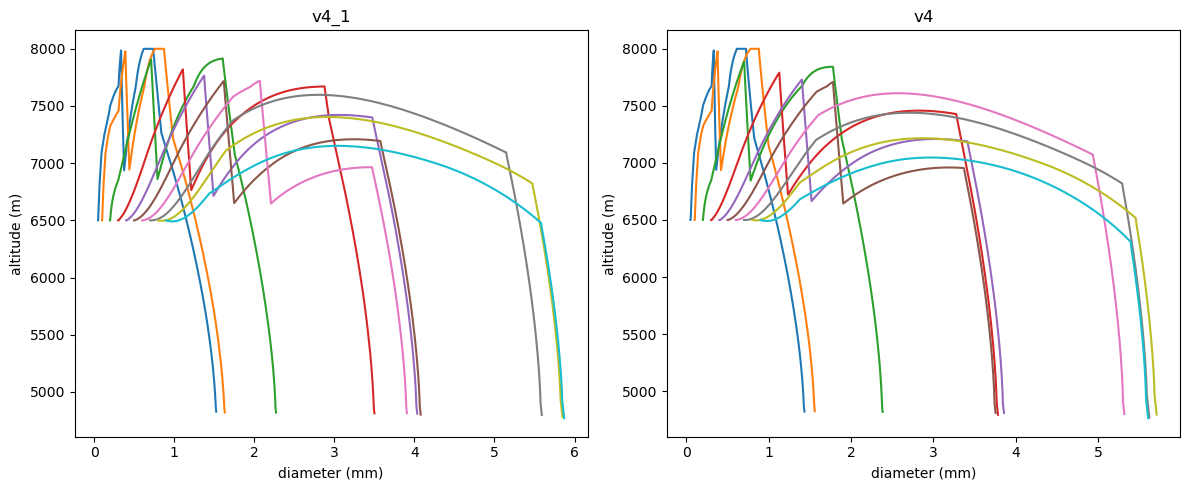

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# First subplot
for s in range(ncfile_ice_v4_1.sizes['particle']):
    p0_ice = ncfile_ice_v4_1.isel(particle=s)
    ax1.plot(p0_ice['diameter']*1000, p0_ice['altitude'])
    ax1.set_xlabel("diameter (mm)")
    ax1.set_ylabel("altitude (m)")

ax1.set_title('v4_1')

# Second subplot
for s in range(ncfile_ice_v4.sizes['particle']):
    p0_ice = ncfile_ice_v4.isel(particle=s)
    ax2.plot(p0_ice['diameter']*1000, p0_ice['altitude'])
    ax2.set_xlabel("diameter (mm)")
    ax2.set_ylabel("altitude (m)")

ax2.set_title('v4')


# Adjust spacing
plt.tight_layout()

# Display
plt.show()




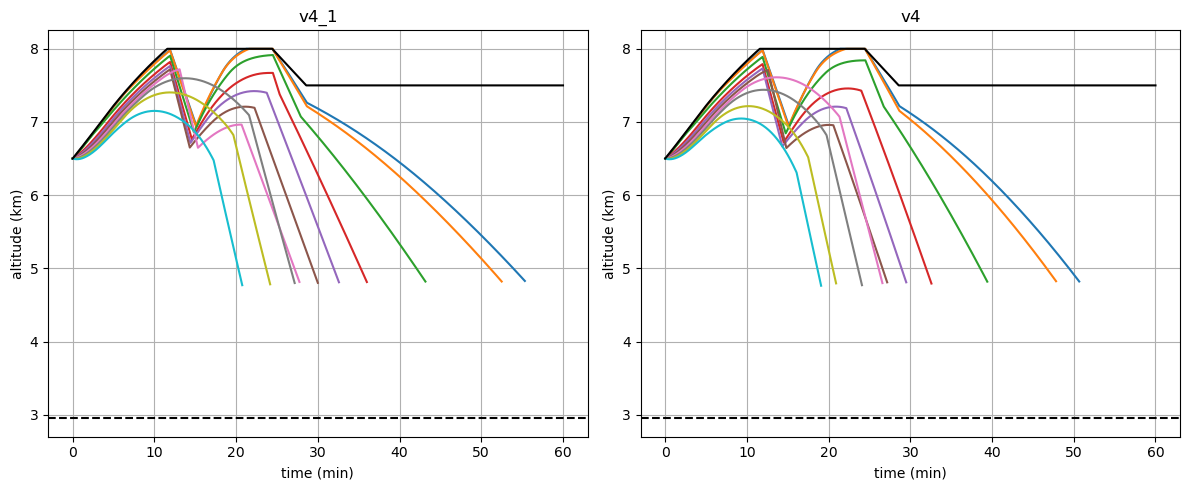

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# First subplot
for s in range(ncfile_ice_v4_1.sizes['particle']):
    p0_ice = ncfile_ice_v4_1.isel(particle=s)
    p0_ice = ncfile_ice_v4_1.isel(particle=s)
    ax1.plot(ncfile_v4_1['time']/60, p0_ice['altitude']/1000)
    ax1.set_xlabel("time (min)")
    ax1.set_ylabel("altitude (km)")

ax1.plot(ncfile_v4_1['time']/60, ncfile_envi_v4_1['cloud_top'],color='black', label='cloud_top')
zbase = ptz(namelist_v4_1['pbase']) # height of cloud base (m)
ax1.axhline(y=zbase/1000, color='black', linestyle='--', label='cloud_base')
ax1.grid()
ax1.set_title('v4_1')

# Second subplot
for s in range(ncfile_ice_v4.sizes['particle']):
    p0_ice = ncfile_ice_v4.isel(particle=s)
    p0_ice = ncfile_ice_v4.isel(particle=s)
    ax2.plot(ncfile_v4['time']/60, p0_ice['altitude']/1000)
    ax2.set_xlabel("time (min)")
    ax2.set_ylabel("altitude (km)")

ax2.plot(ncfile_v4_1['time']/60, ncfile_envi_v4_1['cloud_top'],color='black', label='cloud_top')
zbase = ptz(namelist_v4_1['pbase']) # height of cloud base (m)
ax2.axhline(y=zbase/1000, color='black', linestyle='--', label='cloud_base')
ax2.grid()
ax2.set_title('v4')


# Adjust spacing
plt.tight_layout()

# Display
plt.show()



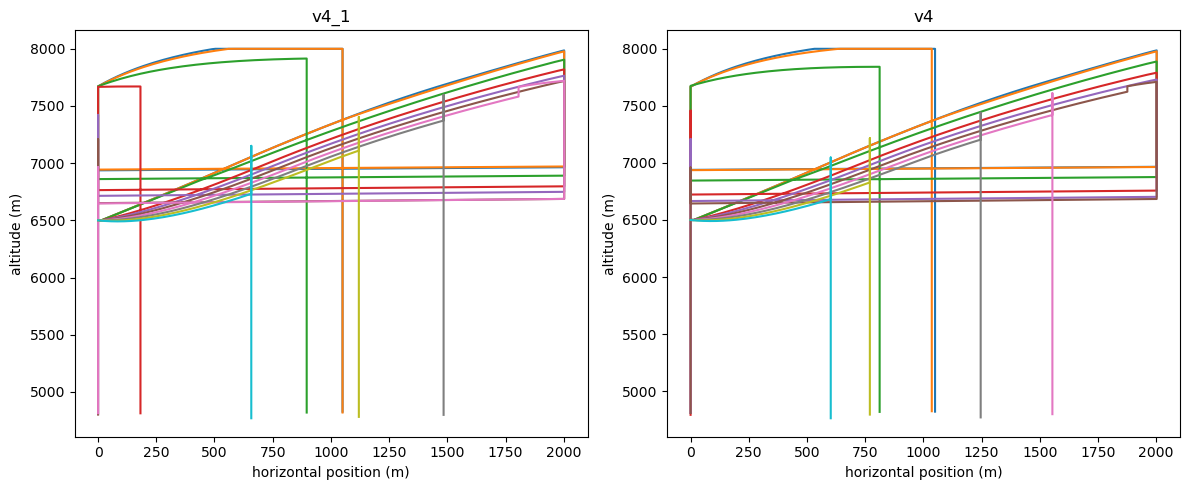

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# First subplot
for s in range(ncfile_ice_v4_1.sizes['particle']):
    p0_ice = ncfile_ice_v4_1.isel(particle=s)
    p0_ice = ncfile_ice_v4_1.isel(particle=s)
    ax1.plot(p0_ice['horizontal_position']*1000, p0_ice['altitude'])
    ax1.set_xlabel("horizontal position (m)")
    ax1.set_ylabel("altitude (m)")

ax1.set_title('v4_1')

# Second subplot
for s in range(ncfile_ice_v4.sizes['particle']):
    p0_ice = ncfile_ice_v4.isel(particle=s)
    p0_ice = ncfile_ice_v4.isel(particle=s)
    ax2.plot(p0_ice['horizontal_position']*1000, p0_ice['altitude'])
    ax2.set_xlabel("horizontal position (m)")
    ax2.set_ylabel("altitude (m)")
ax2.set_title('v4')


# Adjust spacing
plt.tight_layout()

# Display
plt.show()


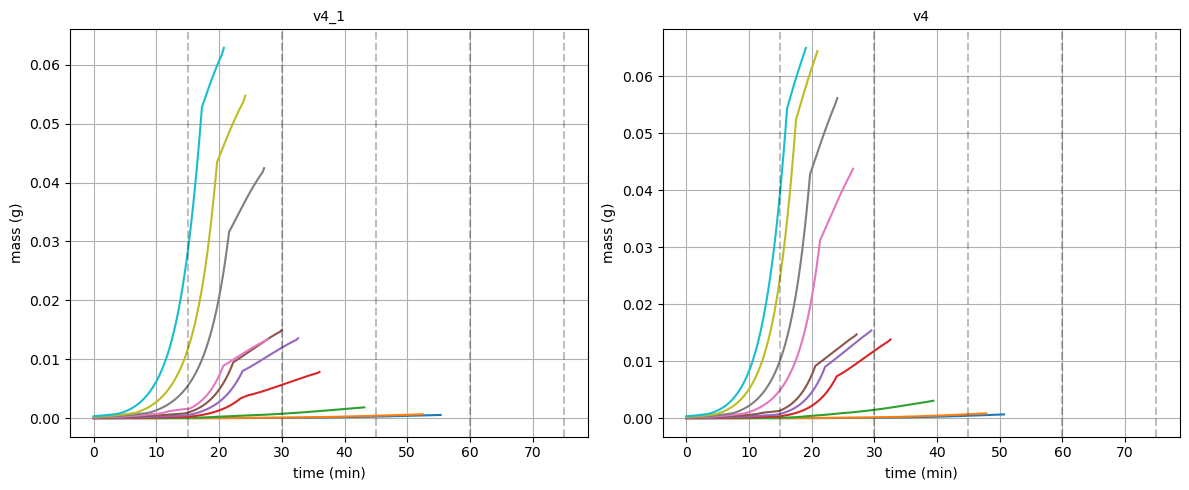

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# First subplot: v4_1
for s in range(ncfile_ice_v4_1.sizes['particle']):
    p0_ice = ncfile_ice_v4_1.isel(particle=s)
    ax1.plot(ncfile_v4_1['time']/60, p0_ice['mass']*1000)

ax1.set_xlabel("time (min)")
ax1.set_ylabel("mass (g)")
ax1.set_title('v4_1', fontsize=10)
ax1.axvline(x=15, color='black', linestyle='--', alpha=0.25)
ax1.axvline(x=30, color='black', linestyle='--', alpha=0.25)
ax1.axvline(x=45, color='black', linestyle='--', alpha=0.25)
ax1.axvline(x=60, color='black', linestyle='--', alpha=0.25)
ax1.axvline(x=75, color='black', linestyle='--', alpha=0.25)
ax1.grid()

# Second subplot: v4
for s in range(ncfile_ice_v4.sizes['particle']):
    p0_ice = ncfile_ice_v4.isel(particle=s)
    ax2.plot(ncfile_v4['time']/60, p0_ice['mass']*1000)

ax2.set_xlabel("time (min)")
ax2.set_ylabel("mass (g)")
ax2.set_title('v4', fontsize=10)
ax2.axvline(x=15, color='black', linestyle='--', alpha=0.25)
ax2.axvline(x=30, color='black', linestyle='--', alpha=0.25)
ax2.axvline(x=45, color='black', linestyle='--', alpha=0.25)
ax2.axvline(x=60, color='black', linestyle='--', alpha=0.25)
ax2.axvline(x=75, color='black', linestyle='--', alpha=0.25)
ax2.grid()

# Adjust spacing
plt.tight_layout()

# Display
plt.show()

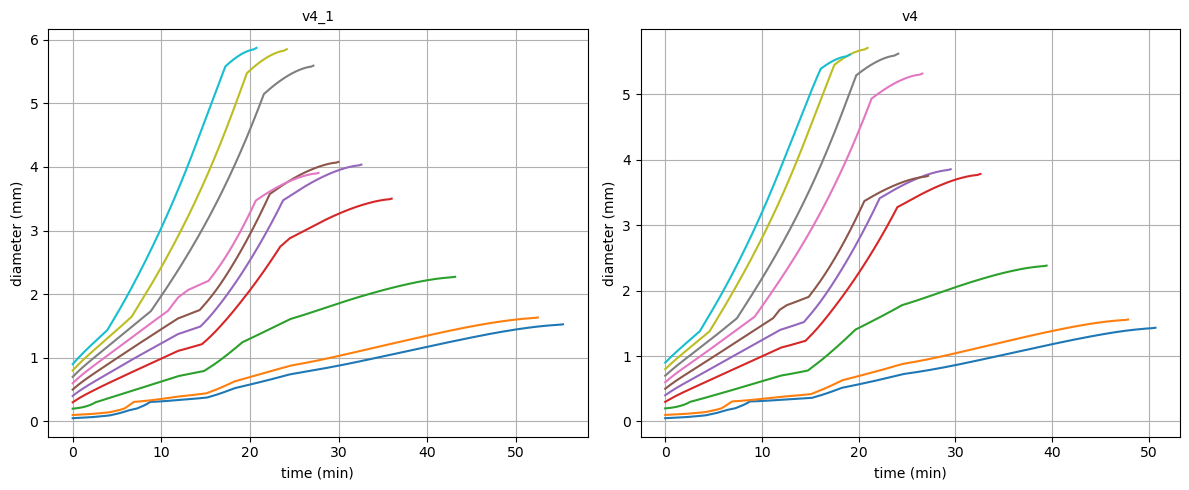

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# First subplot: v4_1
for s in range(ncfile_ice_v4_1.sizes['particle']):
    p0_ice = ncfile_ice_v4_1.isel(particle=s)
    ax1.plot(ncfile_v4_1['time']/60, p0_ice['diameter']*1000)

ax1.set_ylabel("diameter (mm)")
ax1.set_xlabel("time (min)")
ax1.set_title('v4_1', fontsize=10)
ax1.grid()

# Second subplot: v4
for s in range(ncfile_ice_v4.sizes['particle']):
    p0_ice = ncfile_ice_v4.isel(particle=s)
    ax2.plot(ncfile_v4['time']/60, p0_ice['diameter']*1000)

ax2.set_ylabel("diameter (mm)")
ax2.set_xlabel("time (min)")
ax2.set_title('v4', fontsize=10)
ax2.grid()

# Adjust spacing
plt.tight_layout()

# Display
plt.show()

In [40]:
p0_ice['altitude'].max()

<xarray.DataArray 'altitude' ()> Size: 4B
array(7079.3945, dtype=float32)

# 30th tuning?

In [2]:
save_loc_v3_1 = "/gws/ssde/j25a/dcmex/users/ezriab/graupel_model_output/v4_1/" # location to save output files
save_name = 'v4_1_30th_1'
ncfile_v4_1_30th_1 = xr.open_dataset(f"{save_loc_v3_1}{save_name}.nc", decode_times=False)
ncfile_envi_v4_1_30th_1 = xr.open_dataset(f"{save_loc_v3_1}{save_name}.nc", group="environment", engine="netcdf4",decode_times=False)
ncfile_ice_v4_1_30th_1 = xr.open_dataset(f"{save_loc_v3_1}{save_name}.nc", group="ice_particles", engine="netcdf4",decode_times=False)
ncfile_splinter_v4_1_30th_1 = xr.open_dataset(f"{save_loc_v3_1}{save_name}.nc", group="splinter_particles", engine="netcdf4",decode_times=False)

# also pull out the variables put into the namelist file
namelist_file = ncfile_v4_1_30th_1.attrs["namelist_file"]
with open(namelist_file, "r") as f:
    namelist_contents = f.read()
namelist_v4_1_30th_1 = {} ## all the namelist inputs are stored in this dictionary
exec(namelist_contents, {"np": np}, namelist_v4_1_30th_1)

## pull out relevent functions
sys.path.append('/home/users/esree/simple-graupel-model/')
# i have moved all the smaller functions to a seperate file - so can be accessed when plotting too
from graupel_model_sub_functions import trev, ptz

/home/users/esree/miniforge3/envs/vs_code_envi/lib/python3.13/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


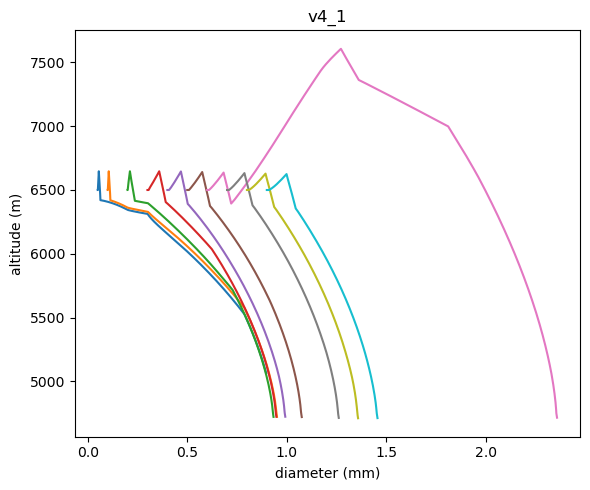

In [3]:
fig, (ax1) = plt.subplots(1, 1, figsize=(6, 5))

# First subplot
for s in range(ncfile_ice_v4_1_30th_1.sizes['particle']):
    p0_ice = ncfile_ice_v4_1_30th_1.isel(particle=s)
    ax1.plot(p0_ice['diameter']*1000, p0_ice['altitude'])
    ax1.set_xlabel("diameter (mm)")
    ax1.set_ylabel("altitude (m)")

ax1.set_title('v4_1')
'''
# Second subplot
for s in range(ncfile_ice_v4.sizes['particle']):
    p0_ice = ncfile_ice_v4.isel(particle=s)
    ax2.plot(p0_ice['diameter']*1000, p0_ice['altitude'])
    ax2.set_xlabel("diameter (mm)")
    ax2.set_ylabel("altitude (m)")

ax2.set_title('v4')
'''

# Adjust spacing
plt.tight_layout()

# Display
plt.show()

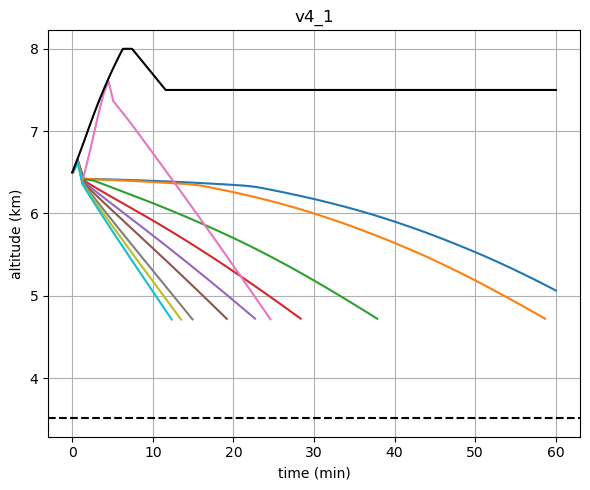

In [4]:
fig, (ax1) = plt.subplots(1, 1, figsize=(6, 5))

# First subplot
for s in range(ncfile_ice_v4_1_30th_1.sizes['particle']):
    p0_ice = ncfile_ice_v4_1_30th_1.isel(particle=s)
    p0_ice = ncfile_ice_v4_1_30th_1.isel(particle=s)
    ax1.plot(ncfile_v4_1_30th_1['time']/60, p0_ice['altitude']/1000)
    ax1.set_xlabel("time (min)")
    ax1.set_ylabel("altitude (km)")

ax1.plot(ncfile_v4_1_30th_1['time']/60, ncfile_envi_v4_1_30th_1['cloud_top'],color='black', label='cloud_top')
zbase = ptz(namelist_v4_1_30th_1['pbase']) # height of cloud base (m)
ax1.axhline(y=zbase/1000, color='black', linestyle='--', label='cloud_base')
ax1.grid()
ax1.set_title('v4_1')
'''
# Second subplot
for s in range(ncfile_ice_v4.sizes['particle']):
    p0_ice = ncfile_ice_v4.isel(particle=s)
    p0_ice = ncfile_ice_v4.isel(particle=s)
    ax2.plot(ncfile_v4['time']/60, p0_ice['altitude']/1000)
    ax2.set_xlabel("time (min)")
    ax2.set_ylabel("altitude (km)")

ax2.plot(ncfile_v4_1['time']/60, ncfile_envi_v4_1['cloud_top'],color='black', label='cloud_top')
zbase = ptz(namelist_v4_1['pbase']) # height of cloud base (m)
ax2.axhline(y=zbase/1000, color='black', linestyle='--', label='cloud_base')
ax2.grid()
ax2.set_title('v4')
'''

# Adjust spacing
plt.tight_layout()

# Display
plt.show()



In [6]:
import sys

sys.path.append('/home/users/esree/dcmex_instruments/faam_data/')
# loads of homemade functions <3 <3
from faam_data_functions import faam_mo_files, time_adjust, get_nc_variable, mask_data, flatten_20hz_variable, mo_mean, datetime_to_sec, cloud_pass_time
from faam_data_functions_v2 import faam_mo_files_v2, cloud_pass_time_v2

faam_mo_paths_dic = faam_mo_files_v2() # dictionary containing dates + paths to nc files
# e.g. faam_mo_paths_dic['date'] ## all paths associated with the date
# 0 = flight name + date
# 1 = faam core path 
# 2 = mo non core path 
faam_mo_paths_dic.keys()

date_dict = faam_mo_paths_dic['220807']
mo_path_64hz = date_dict['mo_non_core'] 

In [7]:
start_times_buf, end_times_buf = cloud_pass_time(mo_path_64hz, sec_buffer=5)
start_times_buf_v2, end_times_buf_v2 = cloud_pass_time_v2(mo_path_64hz, sec_buffer=5)


In [8]:
for i in range(len(start_times_buf)):
    print(f"Cloud pass {i+1}:")
    print(f"Start time (v1): {start_times_buf[i]}")
    print(f"End time (v1): {end_times_buf[i]}")
    print(f"Start time (v2): {start_times_buf_v2[i]}")
    print(f"End time (v2): {end_times_buf_v2[i]}")
    print()

Cloud pass 1:
Start time (v1): 2022-08-07 15:57:58
End time (v1): 2022-08-07 15:58:38
Start time (v2): 2022-08-07 15:57:58
End time (v2): 2022-08-07 15:58:38

Cloud pass 2:
Start time (v1): 2022-08-07 16:05:44
End time (v1): 2022-08-07 16:05:54
Start time (v2): 2022-08-07 16:05:25
End time (v2): 2022-08-07 16:08:29

Cloud pass 3:
Start time (v1): 2022-08-07 16:06:58
End time (v1): 2022-08-07 16:07:44
Start time (v2): 2022-08-07 16:34:02
End time (v2): 2022-08-07 16:34:12

Cloud pass 4:
Start time (v1): 2022-08-07 16:34:02
End time (v1): 2022-08-07 16:34:12
Start time (v2): 2022-08-07 16:37:00
End time (v2): 2022-08-07 16:37:10

Cloud pass 5:
Start time (v1): 2022-08-07 16:57:40
End time (v1): 2022-08-07 16:58:36
Start time (v2): 2022-08-07 16:57:40
End time (v2): 2022-08-07 16:58:36

Cloud pass 6:
Start time (v1): 2022-08-07 17:06:16
End time (v1): 2022-08-07 17:07:17
Start time (v2): 2022-08-07 17:06:16
End time (v2): 2022-08-07 17:07:17

Cloud pass 7:
Start time (v1): 2022-08-07 17:1